# 02 · Models and Kaggle Submission

Input: `data/processed/train_processed.csv`, `data/processed/test_processed.csv` (made by `01_EDA.ipynb`).

Output: `results/model_comparison.csv`, plots in `results/figures/`, the submission file in `submissions/`.

In [5]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, VotingRegressor
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from xgboost import XGBRegressor
#from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
PROCESSED = "../data/processed/"
FIG = "../results/figures/"
sns.set_theme(style="whitegrid")

## C1 · Setup: data, cross-validation and a baseline

- Target: **y = log1p(SalePrice)**. RMSE on y is exactly the Kaggle metric.
- Validation: **5-fold cross-validation**, shuffled, `random_state=42`. Every model is scored on the same 5 folds.

In [6]:
train = pd.read_csv(PROCESSED + "train_processed.csv")
test = pd.read_csv(PROCESSED + "test_processed.csv")

train_ids = train["Id"]
test_ids = test["Id"]
y = np.log1p(train["SalePrice"])
X = train.drop(columns=["Id", "SalePrice"])
X_test = test.drop(columns=["Id"])

print("X:", X.shape, " X_test:", X_test.shape)
assert list(X.columns) == list(X_test.columns)

X: (1458, 262)  X_test: (1459, 262)


In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []

def evaluate(name, model):
    start = time.time()
    scores = -cross_val_score(model, X, y, cv=kf, scoring="neg_root_mean_squared_error")
    results.append({"model": name, "cv_rmse_mean": scores.mean(), "cv_rmse_std": scores.std(),
                    "fold_scores": np.round(scores, 4).tolist(), "time_s": round(time.time() - start, 1)})
    print(f"{name:<28} RMSE = {scores.mean():.4f} ± {scores.std():.4f}   ({time.time() - start:.1f}s)")
    return scores.mean()

**Baseline:** always predict the mean log price. Any real model must beat this.

In [8]:
evaluate("Baseline (mean)", DummyRegressor(strategy="mean"))

Baseline (mean)              RMSE = 0.3993 ± 0.0168   (0.0s)


0.399284908349551

## C2 · Models

I try two families:

- **Linear models** (with `RobustScaler`, which is not sensitive to outliers): plain Linear Regression, Ridge (L2), Lasso (L1, also selects features), ElasticNet (L1 + L2).
- **Tree ensembles:** Random Forest (bagging), Gradient Boosting, XGBoost, LightGBM (boosting). Trees do not need scaling.

### C2.1 Linear Regression

In [9]:
evaluate("Linear Regression", make_pipeline(RobustScaler(), LinearRegression()))

Linear Regression            RMSE = 1255339756.9696 ± 1564425352.7018   (0.2s)


1255339756.9696097

Plain linear regression has no regularization. With 262 columns, many of them correlated or almost always 0, the coefficients become unstable. It already beats the baseline by far, but it is clearly worse than the regularized models below and has the largest spread between folds.

### C2.2 Ridge

In [10]:
evaluate("Ridge (alpha=10)", make_pipeline(RobustScaler(), Ridge(alpha=10)))

Ridge (alpha=10)             RMSE = 0.1136 ± 0.0081   (0.2s)


0.11364950348383056

### C2.3 Lasso

In [11]:
evaluate("Lasso (alpha=0.0005)", make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000)))

Lasso (alpha=0.0005)         RMSE = 0.1116 ± 0.0071   (0.4s)


0.1116047000010214

### C2.4 ElasticNet

In [12]:
evaluate("ElasticNet", make_pipeline(RobustScaler(), ElasticNet(alpha=0.0008, l1_ratio=0.5, max_iter=50000)))

ElasticNet                   RMSE = 0.1119 ± 0.0073   (0.5s)


0.11192889442809861

### C2.5 Random Forest

In [13]:
evaluate("Random Forest", RandomForestRegressor(n_estimators=400, max_features=0.3, n_jobs=-1, random_state=RANDOM_STATE))

Random Forest                RMSE = 0.1284 ± 0.0074   (4.6s)


0.1283765645541203

### C2.6 Gradient Boosting

In [14]:
evaluate("Gradient Boosting", GradientBoostingRegressor(n_estimators=1000, learning_rate=0.05, max_depth=3,
                                                         subsample=0.8, random_state=RANDOM_STATE))

Gradient Boosting            RMSE = 0.1160 ± 0.0048   (35.0s)


0.11603434630185523

### C2.7 XGBoost

In [15]:
xgb = XGBRegressor(n_estimators=1500, learning_rate=0.03, max_depth=3, subsample=0.8,
                   colsample_bytree=0.5, reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=-1)
evaluate("XGBoost", xgb)

XGBoost                      RMSE = 0.1131 ± 0.0061   (9.6s)


0.11310468976386387

### C2.8 LightGBM

In [16]:
lgbm = LGBMRegressor(n_estimators=1500, learning_rate=0.03, num_leaves=8, min_child_samples=10,
                     subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                     random_state=RANDOM_STATE, verbose=-1)
evaluate("LightGBM", lgbm)

NameError: name 'LGBMRegressor' is not defined

**Observations:** all real models beat the baseline (~0.40) by far. Regularized linear models are already very strong (~0.11), because after the log transforms the relation between features and log price is close to linear. Random Forest is the weakest ensemble: it averages deep trees and cannot extrapolate well.

## C3 · Tuning with GridSearchCV

I tune three models on the same 5 folds:
- **Ridge:** `alpha` (strength of L2 penalty)
- **Lasso:** `alpha` (strength of L1 penalty)
- **Gradient Boosting:** `learning_rate`, `max_depth`

In [13]:
ridge_grid = GridSearchCV(make_pipeline(RobustScaler(), Ridge()),
                          {"ridge__alpha": [1, 3, 5, 8, 10, 12, 15, 20, 30, 50]},
                          cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_grid.fit(X, y)
print("best Ridge:", ridge_grid.best_params_, f"RMSE = {-ridge_grid.best_score_:.4f}")

best Ridge: {'ridge__alpha': 20} RMSE = 0.1135


In [14]:
lasso_grid = GridSearchCV(make_pipeline(RobustScaler(), Lasso(max_iter=50000)),
                          {"lasso__alpha": [0.0001, 0.0002, 0.0003, 0.0004, 0.0005, 0.0007, 0.001, 0.002]},
                          cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
lasso_grid.fit(X, y)
print("best Lasso:", lasso_grid.best_params_, f"RMSE = {-lasso_grid.best_score_:.4f}")

best Lasso: {'lasso__alpha': 0.0005} RMSE = 0.1116


In [15]:
gb_grid = GridSearchCV(GradientBoostingRegressor(n_estimators=1000, subsample=0.8, max_features="sqrt",
                                                 random_state=RANDOM_STATE),
                       {"learning_rate": [0.03, 0.05], "max_depth": [3, 4]},
                       cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
gb_grid.fit(X, y)
print("best Gradient Boosting:", gb_grid.best_params_, f"RMSE = {-gb_grid.best_score_:.4f}")

best Gradient Boosting: {'learning_rate': 0.03, 'max_depth': 3} RMSE = 0.1110


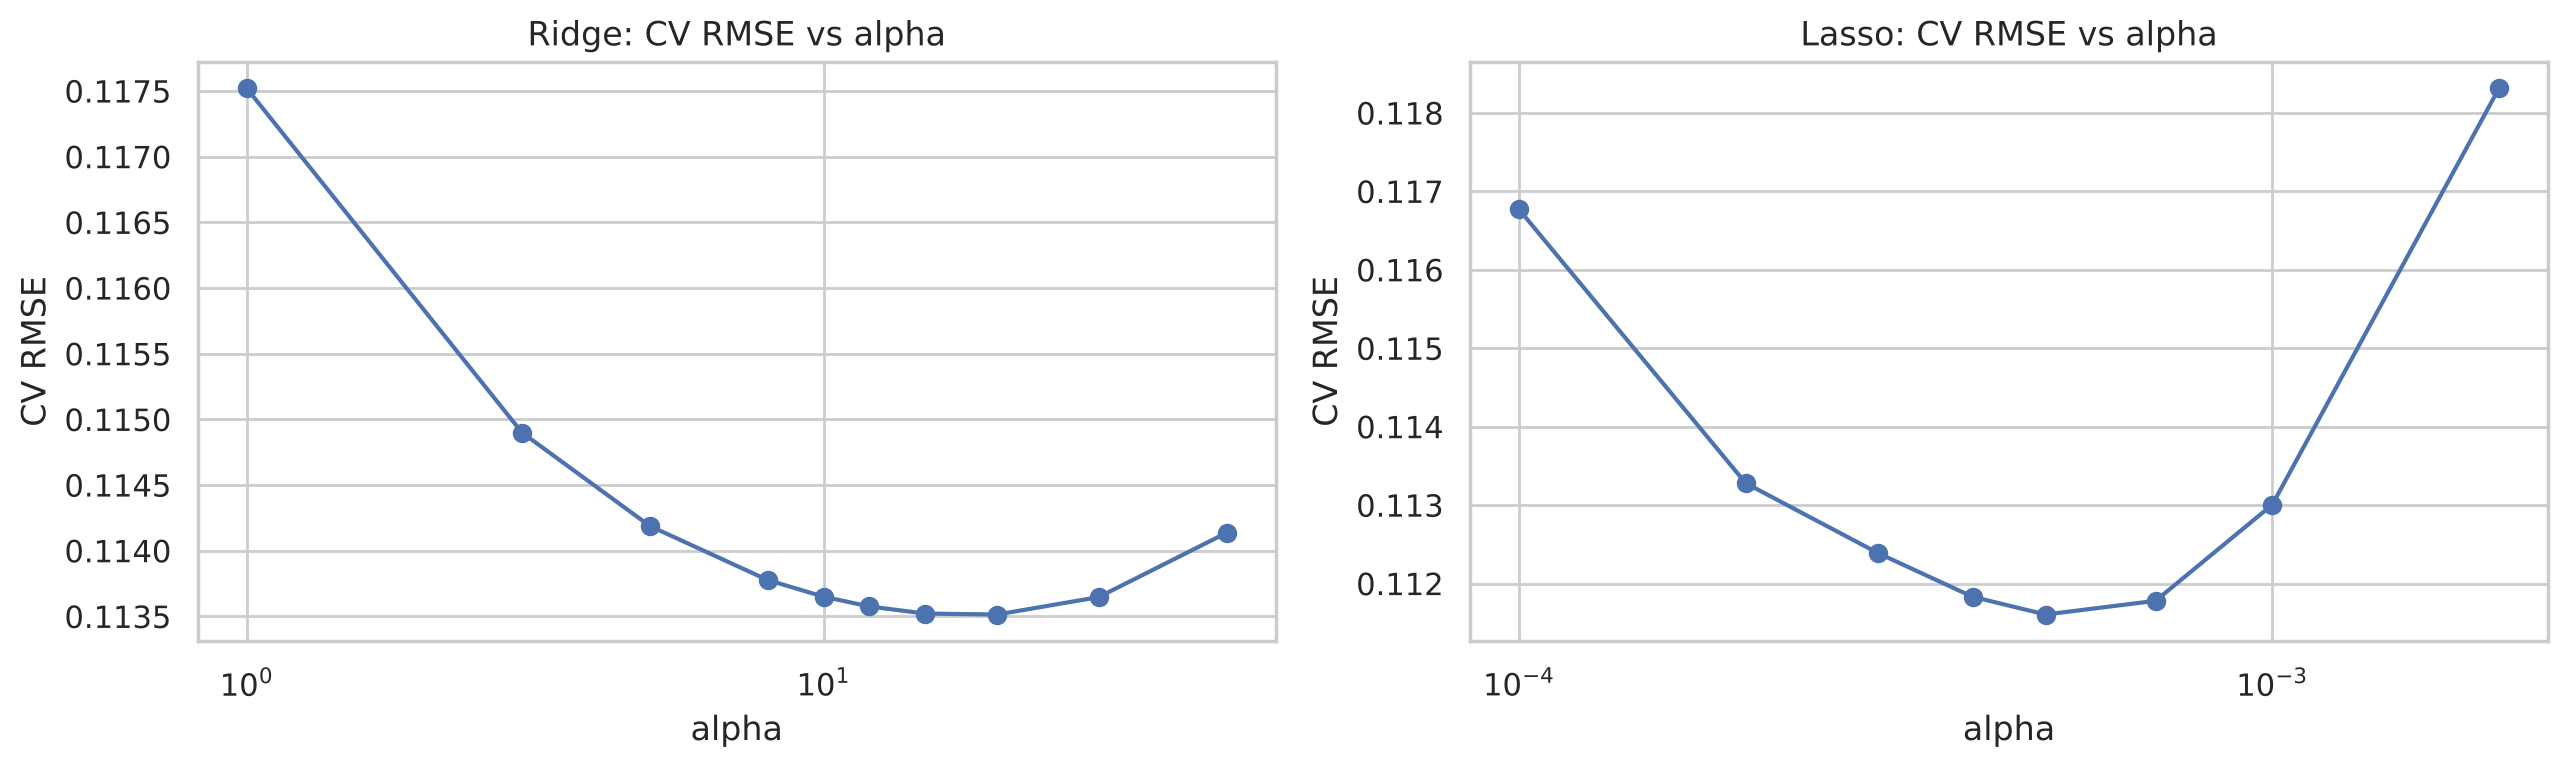

,params,cv_rmse
0,"{'learning_rate': 0.03, 'max_depth': 3}",0.110999
1,"{'learning_rate': 0.03, 'max_depth': 4}",0.113506
2,"{'learning_rate': 0.05, 'max_depth': 3}",0.111526
3,"{'learning_rate': 0.05, 'max_depth': 4}",0.115658


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, grid, p, name in [(axes[0], ridge_grid, "param_ridge__alpha", "Ridge"),
                          (axes[1], lasso_grid, "param_lasso__alpha", "Lasso")]:
    cv = pd.DataFrame(grid.cv_results_)
    ax.plot(cv[p].astype(float), -cv["mean_test_score"], marker="o")
    ax.set_xscale("log")
    ax.set_xlabel("alpha")
    ax.set_ylabel("CV RMSE")
    ax.set_title(f"{name}: CV RMSE vs alpha")
plt.tight_layout()
plt.savefig(FIG + "10_tuning_alpha.png", dpi=120)
plt.show()

pd.DataFrame(gb_grid.cv_results_)[["params", "mean_test_score"]].assign(cv_rmse=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score")

In [17]:
best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_
best_gb = gb_grid.best_estimator_

evaluate(f"Ridge tuned (alpha={ridge_grid.best_params_['ridge__alpha']})", best_ridge)
evaluate(f"Lasso tuned (alpha={lasso_grid.best_params_['lasso__alpha']})", best_lasso)
evaluate("Gradient Boosting tuned", best_gb)

Ridge tuned (alpha=20)       RMSE = 0.1135 ± 0.0081   (0.2s)


Lasso tuned (alpha=0.0005)   RMSE = 0.1116 ± 0.0071   (0.5s)


Gradient Boosting tuned      RMSE = 0.1110 ± 0.0072   (4.3s)


np.float64(0.11099925974408076)

**Ensemble (average).** Linear models and boosted trees make **different kinds** of mistakes, so averaging their predictions usually cancels part of the error. `VotingRegressor` simply averages the predictions of tuned Lasso, tuned Gradient Boosting, XGBoost and LightGBM. It is scored with the same 5-fold CV, so the comparison is fair.

In [18]:
blend = VotingRegressor([("lasso", best_lasso), ("gb", best_gb), ("xgb", xgb), ("lgbm", lgbm)])
evaluate("Average (Lasso+GB+XGB+LGBM)", blend)

Average (Lasso+GB+XGB+LGBM)  RMSE = 0.1085 ± 0.0071   (13.9s)


np.float64(0.10850741570960816)

## C4 · Comparison and winner

In [19]:
comparison = pd.DataFrame(results).sort_values("cv_rmse_mean").reset_index(drop=True)
comparison["cv_rmse_mean"] = comparison["cv_rmse_mean"].round(5)
comparison["cv_rmse_std"] = comparison["cv_rmse_std"].round(5)
comparison.to_csv("../results/model_comparison.csv", index=False)
comparison

,model,cv_rmse_mean,cv_rmse_std,fold_scores,time_s
0,Average (Lasso+GB+XGB+LGBM),0.10851,0.00711,"[0.111, 0.1059, 0.1137, 0.116, 0.096]",13.9
1,Gradient Boosting tuned,0.11100,0.00720,"[0.1131, 0.11, 0.1154, 0.1187, 0.0978]",4.3
2,Lasso (alpha=0.0005),0.11160,0.00706,"[0.1111, 0.1126, 0.1199, 0.1157, 0.0988]",0.6
3,Lasso tuned (alpha=0.0005),0.11160,0.00706,"[0.1111, 0.1126, 0.1199, 0.1157, 0.0988]",0.5
4,ElasticNet,0.11193,0.00728,"[0.1119, 0.1126, 0.1197, 0.1169, 0.0985]",0.6
5,XGBoost,0.11231,0.00580,"[0.114, 0.109, 0.1164, 0.1193, 0.1029]",6.0
6,Ridge tuned (alpha=20),0.11351,0.00809,"[0.1166, 0.112, 0.12, 0.1205, 0.0985]",0.2
7,Ridge (alpha=10),0.11365,0.00812,"[0.116, 0.1138, 0.1193, 0.121, 0.0982]",0.2
8,Gradient Boosting,0.11605,0.00481,"[0.1132, 0.1158, 0.1216, 0.1209, 0.1087]",29.6
9,LightGBM,0.11770,0.00809,"[0.1254, 0.1106, 0.1198, 0.1266, 0.1061]",3.4


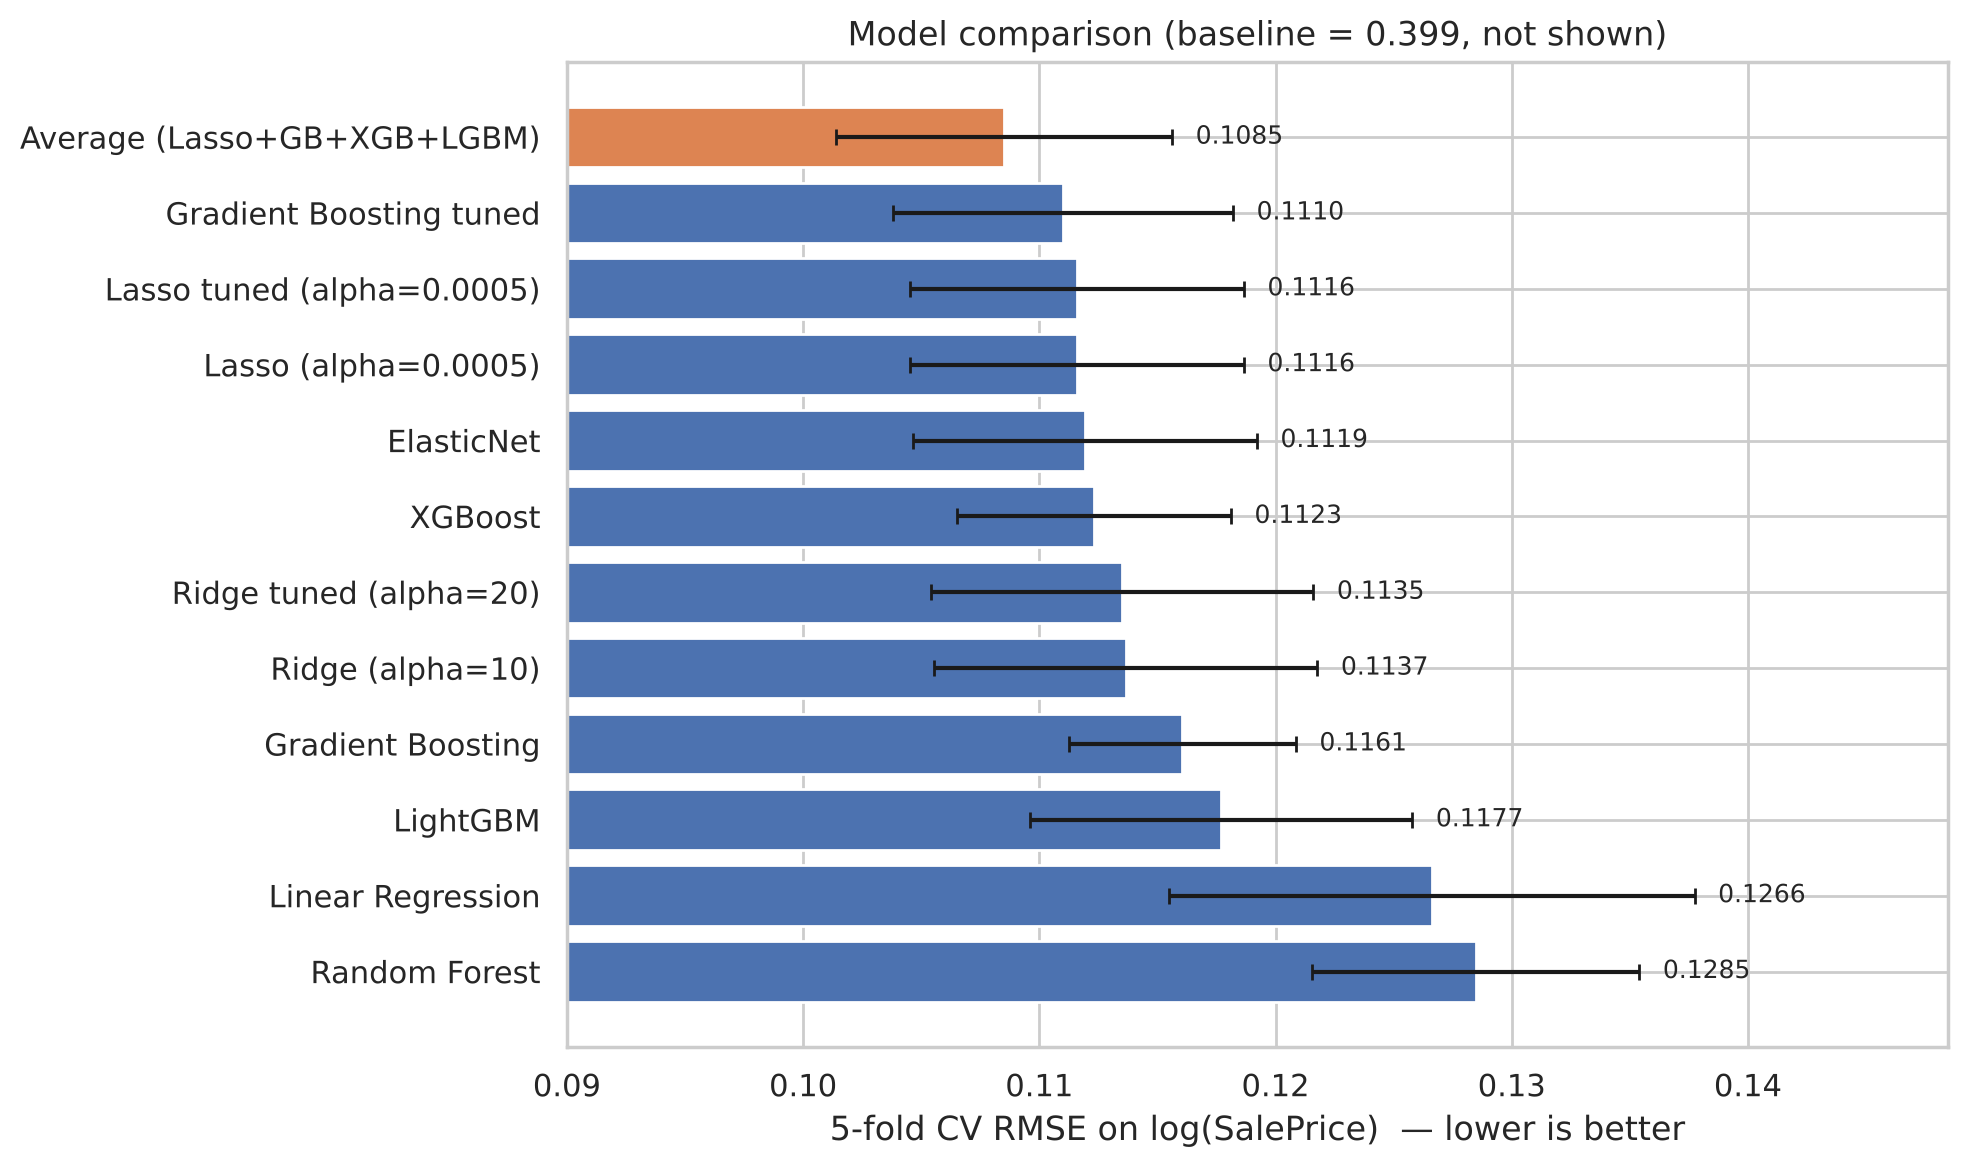

In [20]:
plot_df = comparison[comparison["model"] != "Baseline (mean)"].sort_values("cv_rmse_mean", ascending=False)
plot_df = plot_df[plot_df["cv_rmse_mean"] < 0.3]
baseline = comparison.loc[comparison["model"] == "Baseline (mean)", "cv_rmse_mean"].iloc[0]

plt.figure(figsize=(10, 6))
colors = ["#DD8452" if i == len(plot_df) - 1 else "#4C72B0" for i in range(len(plot_df))]
plt.barh(plot_df["model"], plot_df["cv_rmse_mean"], xerr=plot_df["cv_rmse_std"], color=colors, capsize=3)
for i, (v, sd) in enumerate(zip(plot_df["cv_rmse_mean"], plot_df["cv_rmse_std"])):
    plt.text(v + sd + 0.001, i, f"{v:.4f}", va="center", fontsize=9)
plt.xlabel("5-fold CV RMSE on log(SalePrice)  — lower is better")
plt.title(f"Model comparison (baseline = {baseline:.3f}, not shown)")
plt.xlim(0.09, plot_df["cv_rmse_mean"].max() + 0.02)
plt.tight_layout()
plt.savefig(FIG + "11_model_comparison.png", dpi=120)
plt.show()

In [21]:
winner_name = comparison.loc[0, "model"]
models = {
    "Ridge tuned": best_ridge, "Lasso tuned": best_lasso, "Gradient Boosting tuned": best_gb,
    "Average": blend, "XGBoost": xgb, "LightGBM": lgbm,
}
winner = next(m for k, m in models.items() if winner_name.startswith(k))
print("Winner:", winner_name, f"  CV RMSE = {comparison.loc[0, 'cv_rmse_mean']:.4f}")

Winner: Average (Lasso+GB+XGB+LGBM)   CV RMSE = 0.1085


**Choice of the winner:** the model with the lowest mean CV RMSE. The standard deviation over folds is also small, so the result is stable and not a lucky split. The average beats every single model because the linear part and the tree part make different errors.

## C5 · Error analysis

Out-of-fold predictions with `cross_val_predict`: every house is predicted by a model that **did not see it** during training. Then I look at where the winner makes its biggest mistakes.

In [22]:
oof = cross_val_predict(winner, X, y, cv=kf)
err = pd.DataFrame({"Id": train_ids, "log_true": y, "log_pred": oof})
err["log_error"] = err["log_pred"] - err["log_true"]
err["abs_log_error"] = err["log_error"].abs()
err["true_price"] = np.expm1(err["log_true"]).round()
err["pred_price"] = np.expm1(err["log_pred"]).round()
err["pct_error"] = ((err["pred_price"] - err["true_price"]) / err["true_price"] * 100).round(1)

print(f"OOF RMSE (log): {np.sqrt((err['log_error'] ** 2).mean()):.4f}")
print(f"median absolute error: {(err['pred_price'] - err['true_price']).abs().median():,.0f} $")

OOF RMSE (log): 0.1087
median absolute error: 8,562 $


In [23]:
raw = pd.read_csv("../data/raw/train.csv")
info = raw[["Id", "Neighborhood", "OverallQual", "GrLivArea", "YearBuilt", "SaleCondition"]]
err = err.merge(info, on="Id")
worst = err.sort_values("abs_log_error", ascending=False).head(10)
worst[["Id", "true_price", "pred_price", "pct_error", "Neighborhood", "OverallQual", "GrLivArea", "YearBuilt", "SaleCondition"]]

,Id,true_price,pred_price,pct_error,Neighborhood,OverallQual,GrLivArea,YearBuilt,SaleCondition
30,31,40000.0,85409.0,113.5,IDOTRR,4,1317,1920,Normal
631,633,82500.0,174641.0,111.7,NWAmes,7,1411,1977,Family
462,463,62383.0,122325.0,96.1,Sawyer,5,864,1965,Normal
1322,1325,147000.0,284168.0,93.3,Somerst,8,1795,2006,Partial
495,496,34900.0,61799.0,77.1,IDOTRR,4,720,1920,Abnorml
969,971,135000.0,78435.0,-41.9,NAmes,4,1192,1949,Abnorml
967,969,37900.0,63920.0,68.7,OldTown,3,968,1910,Abnorml
687,689,392000.0,233904.0,-40.3,StoneBr,8,1419,2007,Partial
410,411,60000.0,100347.0,67.2,Edwards,5,1276,1958,Abnorml
88,89,85000.0,52248.0,-38.5,IDOTRR,3,1526,1915,Abnorml


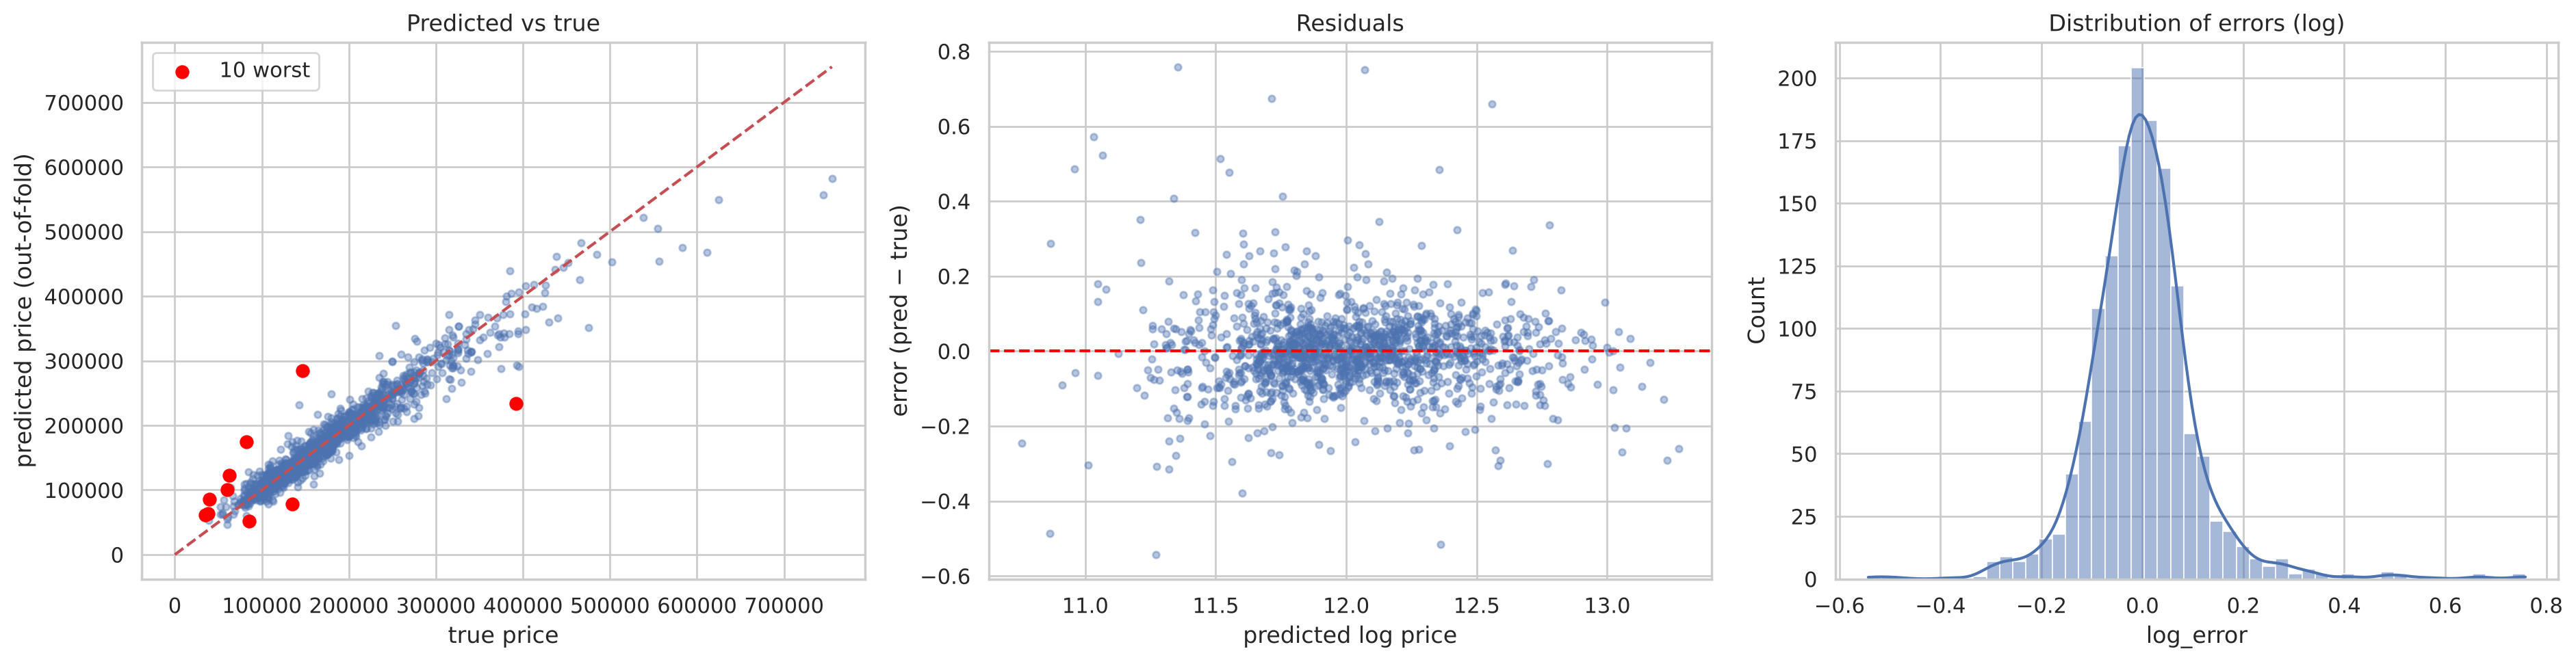

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
axes[0].scatter(err["true_price"], err["pred_price"], alpha=0.4, s=12)
lim = [0, err[["true_price", "pred_price"]].max().max()]
axes[0].plot(lim, lim, "r--")
axes[0].scatter(worst["true_price"], worst["pred_price"], color="red", s=40, label="10 worst")
axes[0].set_xlabel("true price")
axes[0].set_ylabel("predicted price (out-of-fold)")
axes[0].set_title("Predicted vs true")
axes[0].legend()

axes[1].scatter(err["log_pred"], err["log_error"], alpha=0.4, s=12)
axes[1].axhline(0, color="red", ls="--")
axes[1].set_xlabel("predicted log price")
axes[1].set_ylabel("error (pred − true)")
axes[1].set_title("Residuals")

sns.histplot(err["log_error"], bins=50, kde=True, ax=axes[2])
axes[2].set_title("Distribution of errors (log)")
plt.tight_layout()
plt.savefig(FIG + "12_error_analysis.png", dpi=110)
plt.show()

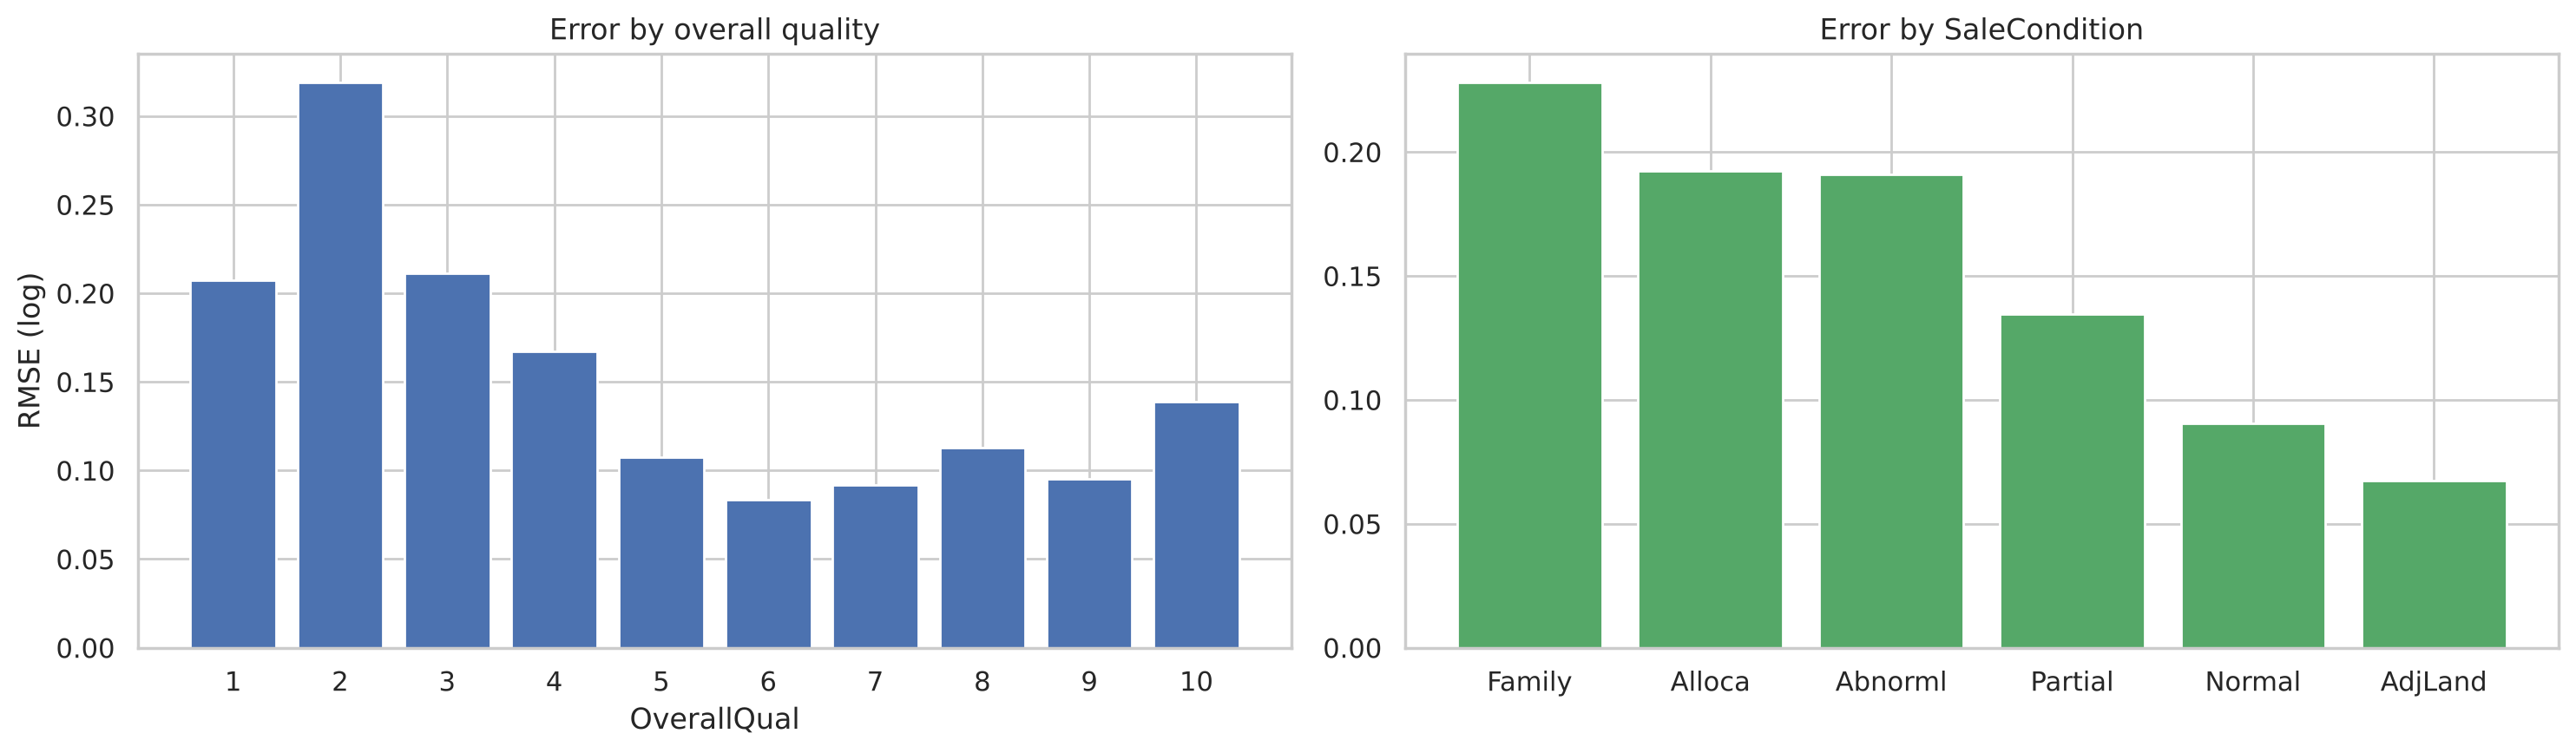

,n,rmse
SaleCondition,,
Family,20,0.2282
Alloca,12,0.1925
Abnorml,101,0.1909
Partial,123,0.1345
Normal,1198,0.0906
AdjLand,4,0.0674


,n,rmse
Neighborhood,,
IDOTRR,37,0.2247
OldTown,113,0.1431
ClearCr,28,0.1389
StoneBr,25,0.1296
Edwards,98,0.1294
SWISU,25,0.1273


In [25]:
by_cond = err.groupby("SaleCondition").agg(n=("Id", "size"), rmse=("log_error", lambda e: np.sqrt((e ** 2).mean()))).sort_values("rmse", ascending=False)
by_qual = err.groupby("OverallQual").agg(n=("Id", "size"), rmse=("log_error", lambda e: np.sqrt((e ** 2).mean())))
by_nb = err.groupby("Neighborhood").agg(n=("Id", "size"), rmse=("log_error", lambda e: np.sqrt((e ** 2).mean()))).sort_values("rmse", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(by_qual.index.astype(str), by_qual["rmse"], color="#4C72B0")
axes[0].set_xlabel("OverallQual")
axes[0].set_ylabel("RMSE (log)")
axes[0].set_title("Error by overall quality")
axes[1].bar(by_cond.index, by_cond["rmse"], color="#55A868")
axes[1].set_title("Error by SaleCondition")
plt.tight_layout()
plt.savefig(FIG + "13_error_by_group.png", dpi=110)
plt.show()

display(by_cond.round(4))
display(by_nb.head(6).round(4))

**Where the winner fails**
- Most houses are predicted well (see the narrow error histogram, centered at 0).
- The biggest mistakes are mostly **over-predictions of cheap houses** (e.g. Id 31: real 40k, predicted ~85k): the house looks normal, so the model predicts a normal price, but it was sold much cheaper.
- 8 of the 10 worst houses were **not normal sales**: `Abnorml` (foreclosure, short sale), `Partial` (new house not finished) or `Family` (sale between relatives). Error for `Normal` sales is ≈ 0.09, for `Abnorml` and `Family` ≈ 0.19–0.23 — the price depends on the **sale situation**, not only on the house.
- Errors are larger for **low and very high quality** houses (`OverallQual` 2–4 and 10): there are few such houses in the data, so the model has less to learn from.
- Old houses in poorer neighborhoods (`IDOTRR`, `OldTown`, `Edwards`) have the highest error — prices vary more there.
- Possible improvements: more features about the sale, removing or down-weighting abnormal sales, more careful tuning of the boosting models.

## C6 · Submission

Fit the winner on **all** training data, predict the test set, turn the log prices back into dollars with `expm1` and save the file.

In [26]:
winner.fit(X, y)
pred_log = winner.predict(X_test)

slug = "average" if winner_name.startswith("Average") else winner_name.split(" (")[0].lower().replace(" ", "_")
submission = pd.DataFrame({"Id": test_ids, "SalePrice": np.expm1(pred_log)})
path = f"../submissions/submission_{slug}.csv"
submission.to_csv(path, index=False)

print("saved:", path)
print("shape:", submission.shape)
assert submission.shape == (1459, 2)
assert submission["SalePrice"].notna().all() and (submission["SalePrice"] > 0).all()
submission.head()

saved: ../submissions/submission_average.csv
shape: (1459, 2)


,Id,SalePrice
0,1461,121905.553189
1,1462,157518.187269
2,1463,185060.153175
3,1464,196316.058181
4,1465,187669.186652


In [27]:
submission["SalePrice"].describe().round(0)

count      1459.0
mean     178388.0
std       78681.0
min       41913.0
25%      127220.0
50%      157079.0
75%      209524.0
max      782231.0
Name: SalePrice, dtype: float64

### Kaggle result
| File | CV RMSE (5-fold) | Kaggle Public Score |
|---|---|---|
| `submission_average.csv` | 0.1085 | **0.12543** |

